<a href="https://colab.research.google.com/github/ElofssonLab/kb8029-book/blob/main/notebooks/session02-plotting-gallery.ipynb" style="display:inline-block;padding:10px 18px;background-color:#F9AB00;color:#000000;font-weight:bold;text-decoration:none;border-radius:6px;font-family:sans-serif;font-size:14px;">&#9654;&nbsp; Open in Google Colab</a>

# Session 2 (optional) — Plotting in Python {.unnumbered}

This notebook is **optional**: nothing in the labs or the exam depends on it. It shows what the
main Python plotting libraries are good at, all on the same table as the Session 2 page (mouse
liver RNA-seq, Becares et al. 2019), so that you know which one to reach for and where to look
later. It is not a complete tutorial; each library's gallery (linked at the end) shows far more.

| Library | What it is for | The nearest thing in R |
|---|---|---|
| **matplotlib** | the foundation: full control of every line, label and axis | base graphics (`plot`, `hist`, `par`) |
| **seaborn** | statistical plots straight from a DataFrame, by column name | `ggplot2` in spirit (`hue=` is `colour =`) |
| **plotnine** | the grammar of graphics: almost word for word `ggplot2` | `ggplot2` itself |
| **plotly** | interactive plots: hover, zoom, pan, hide groups | `plotly` (the same library), `ggplotly()` |

seaborn and plotnine are built on matplotlib, so matplotlib's commands (axis labels, log scales,
saving) work on their figures too. Run the notebook on Colab: plotly and the sliders need a
running notebook, and show nothing (or a static picture) on the course website.

In [1]:
# Install the libraries Colab does not come with (does nothing if they are already installed)
import importlib.util, subprocess, sys
for module, package in [("plotnine", "plotnine"), ("plotly", "plotly"), ("ipywidgets", "ipywidgets")]:
    if importlib.util.find_spec(module) is None:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True)

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

url = "https://raw.githubusercontent.com/JoachimGoedhart/VolcaNoseR/master/Becares-diffgenes_HFHC.csv"
df = pd.read_csv(url)                       # loaded once; every plot below reuses it
df["log10_mean"] = np.log10(df["baseMean"])
df["significant"] = df["padj"] < 0.05
df["direction"] = np.where(~df["significant"], "not significant",
                           np.where(df["log2_FoldChange"] > 0, "up", "down"))
print(df.shape)
df["direction"].value_counts()

(3001, 12)


direction
not significant    2345
down                390
up                  266
Name: count, dtype: int64

This is the notebook advantage from the Session 2 page in practice: the data are loaded
**once**, in the cell above, and every cell below only draws. Change a plot and re-run just its
cell; nothing is read or computed again. (In R you work the same way in the console or in RStudio
with an R Markdown or Quarto document, one chunk at a time.)

## 1. matplotlib: one step per cell

matplotlib has two ways of working. `plt.scatter(...)`, `plt.xlabel(...)` act on "the current
figure", like base R's `plot()` followed by `abline()` and `text()`. The other way keeps the
figure and its axes as objects, `fig, ax = plt.subplots()`, and calls methods on them. Use the
second way: it says which panel each command applies to, and a later cell can still change the
figure. The figure below is built in four small steps.

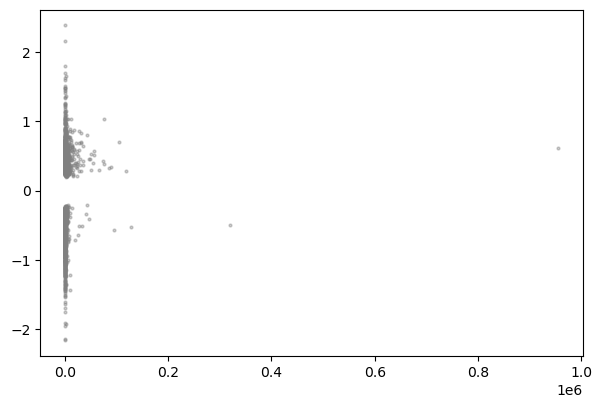

In [3]:
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.scatter(df["baseMean"], df["log2_FoldChange"], s=4, alpha=0.4, color="grey");
# a figure made in a cell is drawn at its end; the next cells change the same figure and show it with `fig`

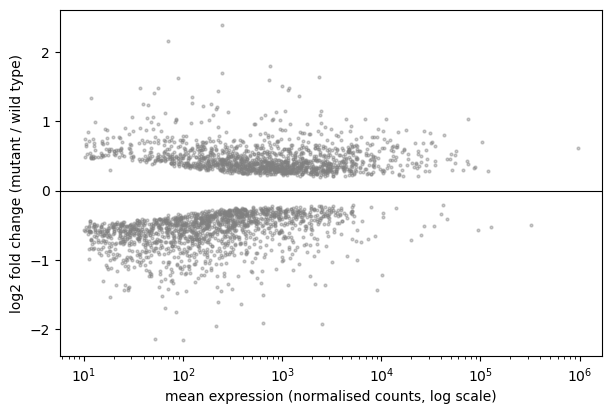

In [4]:
ax.set_xscale("log")                                   # expression spans five orders of magnitude
ax.axhline(0, color="black", lw=0.8)
ax.set_xlabel("mean expression (normalised counts, log scale)")
ax.set_ylabel("log2 fold change (mutant / wild type)")
fig

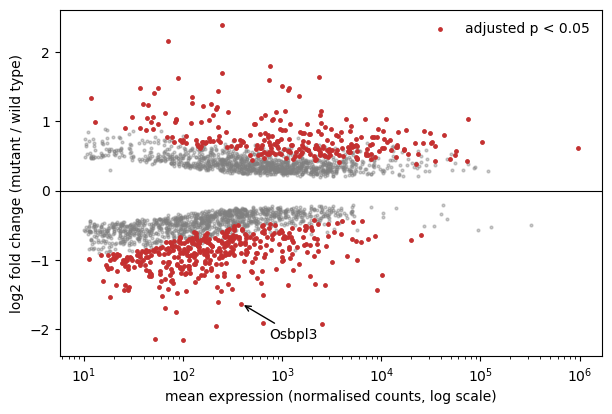

In [5]:
sig = df[df["significant"]]
ax.scatter(sig["baseMean"], sig["log2_FoldChange"], s=6, color="#c53030", label="adjusted p < 0.05")
ax.legend(frameon=False)

top = df.sort_values("padj").iloc[0]                  # the most significant gene, Osbpl3
ax.annotate(top["Gene"], xy=(top["baseMean"], top["log2_FoldChange"]), xytext=(20, -25),
            textcoords="offset points", arrowprops=dict(arrowstyle="->"))
fig

In [6]:
fig.savefig("fold_change_vs_expression.png", dpi=300, bbox_inches="tight")   # like ggsave() or png() ... dev.off()
print("saved; in Colab, find the file in the Files panel on the left")

saved; in Colab, find the file in the Files panel on the left


Three conventions worth copying: give a figure for a report or paper **no title** (the caption
says what it shows), label every axis with its **units**, and save at **300 dpi or more** with
`bbox_inches="tight"` so that labels are not cut off.

Two things that differ from R:

- In R, `plot()` draws immediately. In a notebook, matplotlib draws a figure at the **end of the
  cell**; to change it in a later cell, keep `fig` and `ax` and show `fig` again, as above.
- A cell whose last line returns a matplotlib object also prints it, as text such as
  `<matplotlib.collections.PathCollection at 0x...>`. End the line with `;` or call `plt.show()`
  to hide it.

**Several panels** are `plt.subplots(rows, columns)`, the equivalent of `par(mfrow = c(1, 3))`:

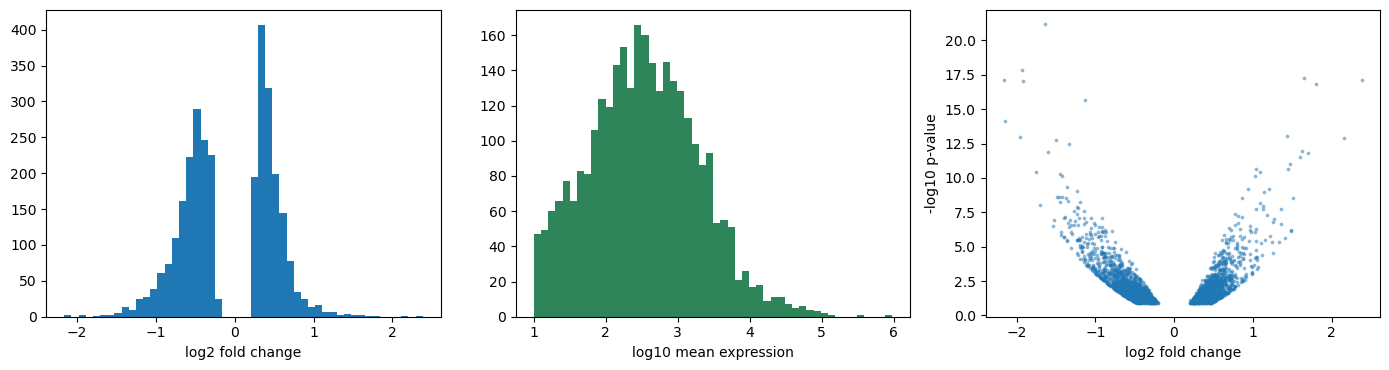

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].hist(df["log2_FoldChange"], bins=50)
axes[0].set_xlabel("log2 fold change")
axes[1].hist(df["log10_mean"], bins=50, color="#2f855a")
axes[1].set_xlabel("log10 mean expression")
axes[2].scatter(df["log2_FoldChange"], df["minus_log10_pvalue"], s=3, alpha=0.4)
axes[2].set_xlabel("log2 fold change"); axes[2].set_ylabel("-log10 p-value")
fig.tight_layout()

pandas has a shortcut that calls matplotlib for you, `df.plot` (like R's `plot(df$x, df$y)`):
handy for a quick look, but you soon want the control above.

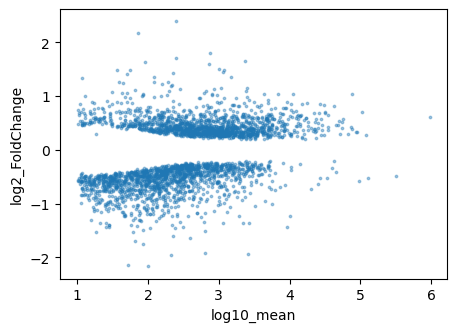

In [8]:
df.plot.scatter(x="log10_mean", y="log2_FoldChange", s=3, alpha=0.4, figsize=(5, 3.5));

## 2. seaborn: statistics by column name

seaborn takes a DataFrame and column names, and does the statistics (counting, smoothing,
fitting, confidence intervals) itself. `hue=` colours by a column, as `colour =` does in an
`aes()` in ggplot2, and the legend comes for free.

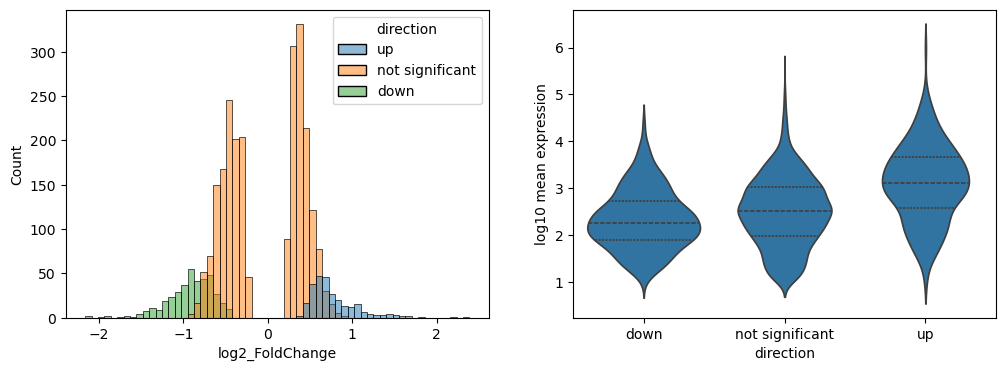

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(data=df, x="log2_FoldChange", hue="direction", bins=60, ax=axes[0])
sns.violinplot(data=df, x="direction", y="log10_mean", order=["down", "not significant", "up"],
               inner="quartile", ax=axes[1])
axes[1].set_ylabel("log10 mean expression");

Are the up- and down-regulated genes expressed at different levels? The violins (a smoothed
histogram turned on its side, with the quartiles marked) answer it at a glance, which is the
question of the lab's third optional challenge.

**A fitted line with its uncertainty.** `regplot` fits a straight line and shades its 95%
confidence band. The band is narrow where there are many points and widens towards the ends:
the fit is trustworthy only where the data are, and saying anything outside that range is
extrapolation. (In R: `geom_smooth(method = "lm")`.)

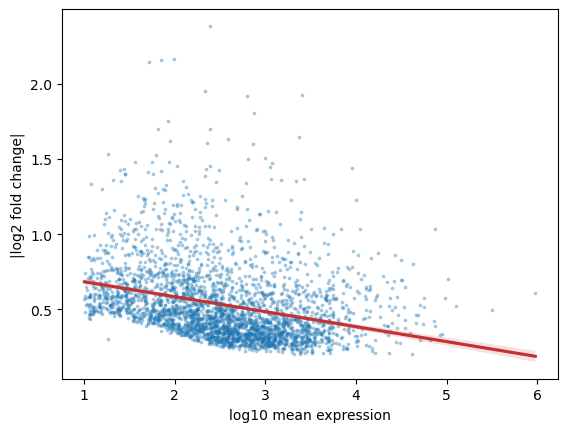

In [10]:
df["abs_log2_fc"] = df["log2_FoldChange"].abs()
ax = sns.regplot(data=df, x="log10_mean", y="abs_log2_fc", scatter_kws=dict(s=3, alpha=0.3),
                 line_kws=dict(color="#c53030"))
ax.set_xlabel("log10 mean expression"); ax.set_ylabel("|log2 fold change|");

**Small multiples.** The "figure-level" functions (`relplot`, `displot`, `catplot`) split
the data into panels by a column with `col=`, like `facet_wrap()`:

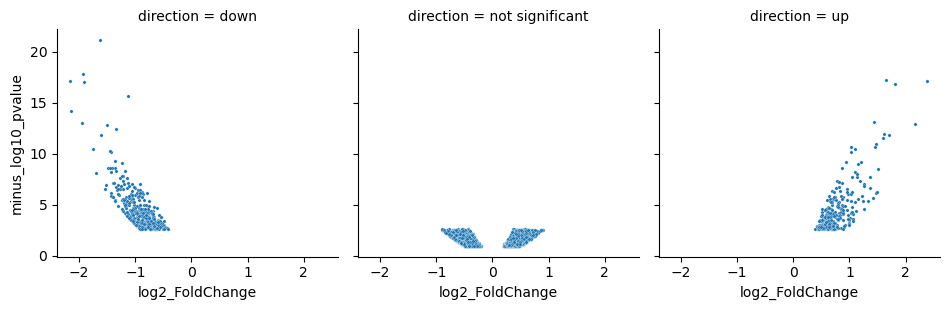

In [11]:
sns.relplot(data=df, x="log2_FoldChange", y="minus_log10_pvalue", col="direction",
            col_order=["down", "not significant", "up"], s=6, height=3.2);

**Many variables at once.** A pair plot draws every pair of columns (`pairs()` in R); a
heatmap shows a matrix, here the correlations between the numeric columns.

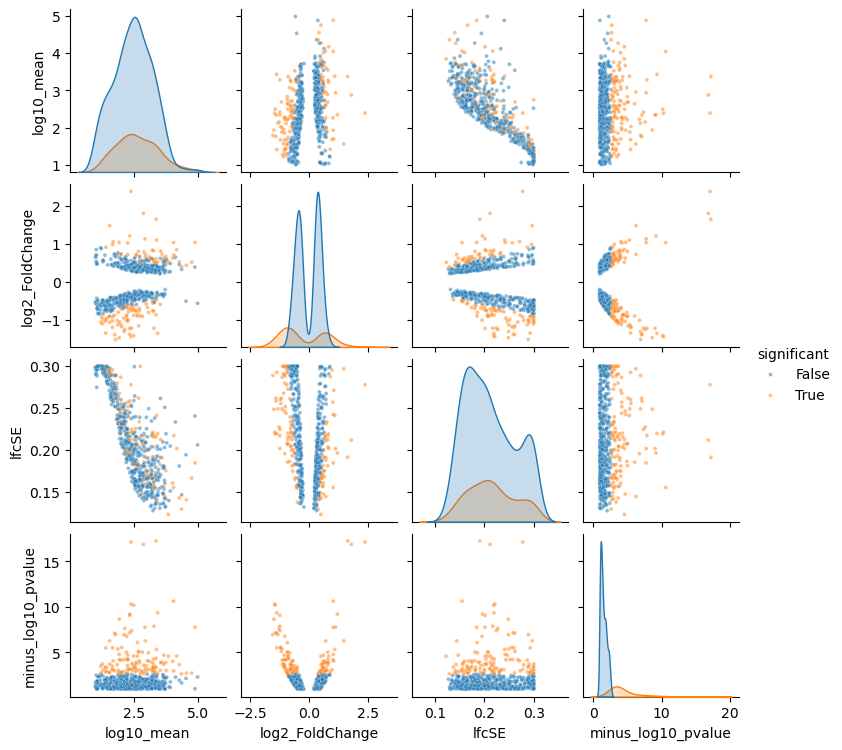

In [12]:
cols = ["log10_mean", "log2_FoldChange", "lfcSE", "minus_log10_pvalue"]
sns.pairplot(df.sample(600, random_state=1), vars=cols, hue="significant",
             plot_kws=dict(s=8, alpha=0.5), height=1.9);

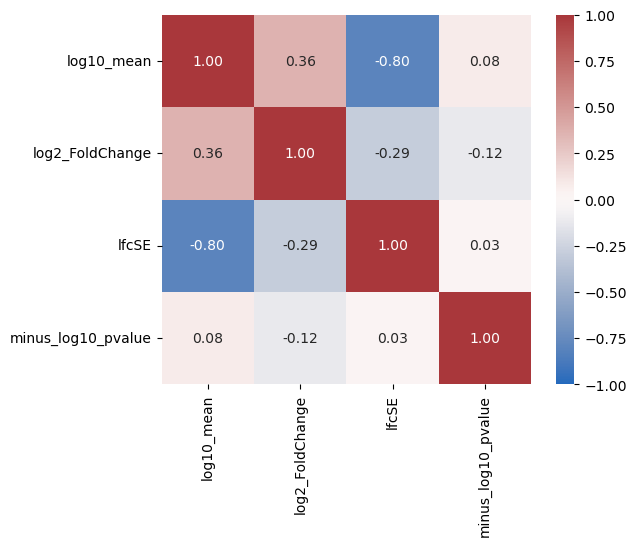

In [13]:
corr = df[cols].corr(method="spearman")
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1, square=True);

The strongest correlation, −0.80, is between expression and the standard error of the fold
change (`lfcSE`): lowly expressed genes have few reads, so their fold changes are measured less
precisely. This is the same noise the Session 2 page found behind their larger fold changes.

## 3. plotnine: ggplot2 in Python

If you learnt `ggplot2` in your R course, plotnine lets you keep that way of thinking: data,
aesthetic mappings, geoms, scales, facets and themes, added together with `+`. The code is almost
the R code; the differences are that column names are strings, and a long expression is wrapped
in brackets so that it can span several lines.

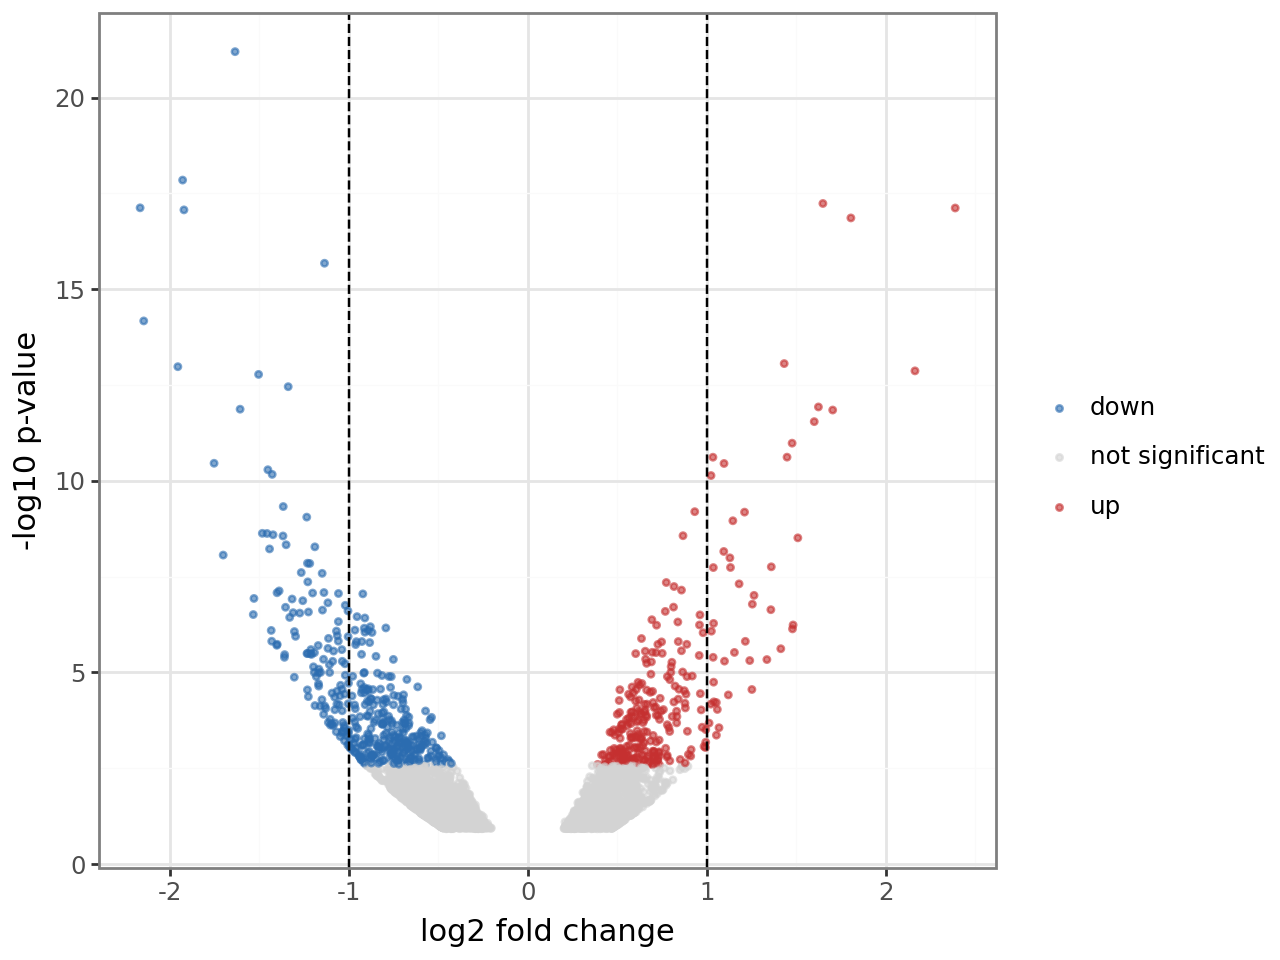

In [14]:
from plotnine import (ggplot, aes, geom_point, geom_hline, geom_vline, scale_colour_manual,
                      facet_wrap, labs, theme_bw)

(ggplot(df, aes(x="log2_FoldChange", y="minus_log10_pvalue", colour="direction"))
 + geom_point(size=0.8, alpha=0.6)
 + geom_vline(xintercept=[-1, 1], linetype="dashed")
 + scale_colour_manual(values={"down": "#2b6cb0", "not significant": "lightgrey", "up": "#c53030"})
 + labs(x="log2 fold change", y="-log10 p-value", colour="")
 + theme_bw())

The same plot in R would read:

```r
ggplot(df, aes(x = log2_FoldChange, y = minus_log10_pvalue, colour = direction)) +
  geom_point(size = 0.8, alpha = 0.6) +
  geom_vline(xintercept = c(-1, 1), linetype = "dashed") +
  scale_colour_manual(values = c(down = "#2b6cb0", `not significant` = "lightgrey", up = "#c53030")) +
  labs(x = "log2 fold change", y = "-log10 p-value", colour = "") +
  theme_bw()
```

`facet_wrap`, `ggsave` and most of the other functions are there too:

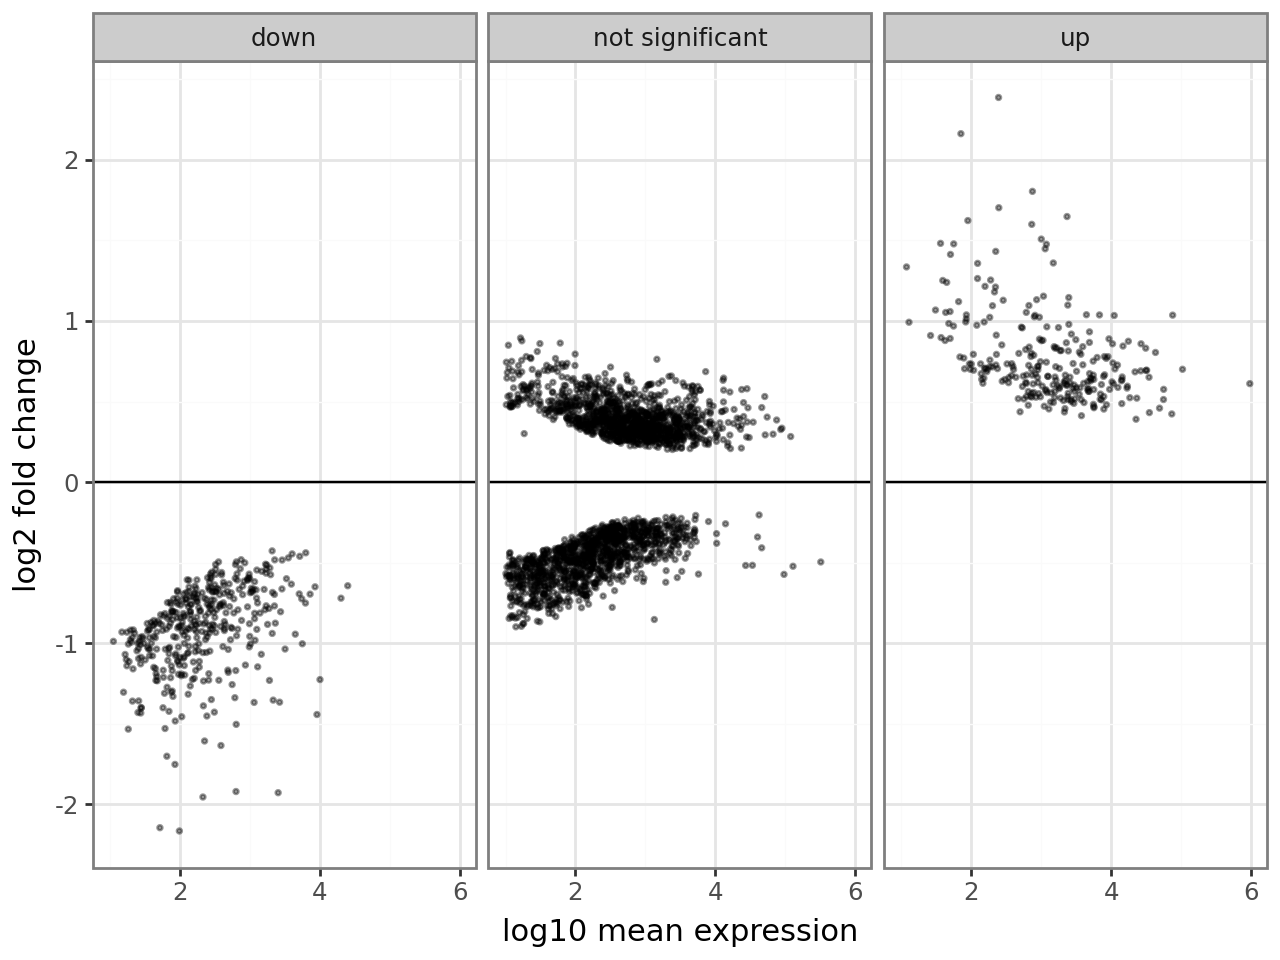

In [15]:
(ggplot(df, aes(x="log10_mean", y="log2_FoldChange"))
 + geom_point(size=0.5, alpha=0.4)
 + geom_hline(yintercept=0)
 + facet_wrap("~direction")
 + labs(x="log10 mean expression", y="log2 fold change")
 + theme_bw())

## 4. plotly: plots you can explore

Every library so far draws a picture. plotly draws an **interactive** plot in the notebook: hover
over a point to see which gene it is, drag to zoom, double-click to zoom out, and click a group in
the legend to hide it. When you explore a new table this beats a static plot: the first question
about an outlier is always "which gene is that?". `plotly.express` takes a DataFrame and column
names, like seaborn.

In [16]:
import plotly.express as px

fig = px.scatter(df, x="log2_FoldChange", y="minus_log10_pvalue", color="direction",
                 hover_name="Gene", hover_data={"baseMean": ":.0f", "padj": ":.1e"},
                 color_discrete_map={"down": "#2b6cb0", "not significant": "lightgrey", "up": "#c53030"},
                 labels={"log2_FoldChange": "log2 fold change", "minus_log10_pvalue": "-log10 p-value"},
                 width=750, height=480)
fig.show()

Try it: which gene is the highest point? Which up-regulated gene has the largest fold
change? Zoom in on the cloud near the origin.

`fig.write_html("volcano.html")` saves the plot as a web page that anyone can open in a browser,
with the interaction intact: a good way to share an exploration with a colleague. For a paper
you still want a static figure (`fig.write_image` needs an extra package, `kaleido`). R has the
same library (`plot_ly()`), and `ggplotly()` turns a ggplot2 plot into a plotly one.

In [17]:
fig = px.scatter(df, x="baseMean", y="log2_FoldChange", color="direction", log_x=True,
                 hover_name="Gene", opacity=0.6, width=750, height=420,
                 color_discrete_map={"down": "#2b6cb0", "not significant": "lightgrey", "up": "#c53030"})
fig.show()

## 5. Sliders: change a parameter, see the result

A notebook can also put controls next to a plot. `interact` from ipywidgets turns a function's
arguments into sliders and calls the function again whenever a slider moves. Here the two
thresholds of a volcano plot are sliders: watch how many genes are called "changed" as you move
them. This works only in a running notebook (on Colab, run the cell first).

In [18]:
from ipywidgets import interact, FloatSlider

@interact(max_padj=FloatSlider(value=0.05, min=0.001, max=0.2, step=0.001, readout_format=".3f"),
          min_abs_fc=FloatSlider(value=1.0, min=0.0, max=3.0, step=0.1))
def volcano(max_padj, min_abs_fc):
    called = (df["padj"] < max_padj) & (df["log2_FoldChange"].abs() > min_abs_fc)
    fig, ax = plt.subplots(figsize=(6.5, 4))
    ax.scatter(df["log2_FoldChange"], df["minus_log10_pvalue"], s=3, color="lightgrey")
    ax.scatter(df.loc[called, "log2_FoldChange"], df.loc[called, "minus_log10_pvalue"], s=5, color="#c53030")
    ax.axvline(-min_abs_fc, ls="--", color="grey"); ax.axvline(min_abs_fc, ls="--", color="grey")
    ax.set_xlabel("log2 fold change"); ax.set_ylabel("-log10 p-value")
    ax.set_title(f"{called.sum()} genes called changed")
    plt.show()

interactive(children=(FloatSlider(value=0.05, description='max_padj', max=0.2, min=0.001, readout_format='.3f'…

## 6. Which one to use

- **A quick look** while exploring: `df.plot`, or seaborn.
- **A statistical summary** (distributions, groups, fits, facets): seaborn, or plotnine if you
  think in ggplot2.
- **Which point is that?** plotly, then make the final figure with one of the others.
- **A figure for a report or paper**: whichever you like, then matplotlib's commands to finish
  it (`ax.set_xlabel`, `ax.set_xscale`, `fig.savefig`).

You do not need all four. Most of this course uses matplotlib with a little seaborn; pick one
more if you find you need it. When you want a plot type you have not seen, look it up in a
gallery, copy the closest example, and change it.

## 7. Try it yourself

1. In the matplotlib section, label the five most significant genes instead of only one.
   (Hint: loop over `df.sort_values("padj").head(5).itertuples()`.)
2. Make the violin plot of section 2 with plotnine (`geom_violin`), then with plotly
   (`px.violin`, with `points="all"` and `hover_name="Gene"`).
3. Add a slider for the point size to the `volcano` function of section 5.

## Further reading

- [matplotlib gallery](https://matplotlib.org/stable/gallery/index.html) and its
  [quick start guide](https://matplotlib.org/stable/users/explain/quick_start.html)
- [seaborn gallery](https://seaborn.pydata.org/examples/index.html) and
  [tutorial](https://seaborn.pydata.org/tutorial.html)
- [plotnine gallery](https://plotnine.org/gallery/), useful together with any ggplot2 material from your R course
- [plotly express](https://plotly.com/python/plotly-express/)
- [ipywidgets: interact](https://ipywidgets.readthedocs.io/en/stable/examples/Using%20Interact.html)
- MolSSI, [Creating plots in Jupyter notebooks](https://education.molssi.org/python-scripting-biochemistry/chapters/Creating_Plots_in_Jupyter_Notebooks.html):
  a step-by-step matplotlib and seaborn example on a protein assay (Bradford) calibration curve